# Bedroom Humidity Forecasting


***

#### Notebook Overview


#### Data Overview

***
#### Key Findings

#### Next Steps

## Imports

In [1]:
# preprocessing
from utils import DataCleanPipleLine

# funcs
from utils.useful_funcs import season_decomp
from utils.ml_pipeline import *
# viz
import matplotlib.pyplot as plt
import seaborn as sns
from utils import plotting as plot

# files
import os

# time series eda

# ACF / PACF (numeric values and plots)
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Stationarity tests
from statsmodels.tsa.stattools import adfuller, kpss

# models

# ARIMA / SARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX   # SARIMA = SARIMAX without exog

# Gradient boosting
from xgboost import XGBRegressor

# Random forest and linear regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

## Data Import

In [2]:

# import data
file_location = os.getenv("F_LOC")

# run data load
cleaning_pipeline = DataCleanPipleLine
pipe_obj = cleaning_pipeline.DataImportAndCleaningPipeline(file_location)

# run pipeline
window_df = pipe_obj.RunPipeline(impute_missing_data=True)



****************************************************************************************************
DF Shape: (257846, 4)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)    Pressure   Humidity
257845  2026-11-17 13:38:35             15.75  961.574400  61.530272
257846  2026-11-17 13:39:35             15.78  961.625200  61.434570
257847  2026-11-17 13:40:35             15.80  961.501700  61.382812
257848  2026-11-17 13:41:35             15.84  961.506600  61.309570
257849  2026-11-17 13:42:35             15.88  961.537968  61.291992
257850  2026-11-17 13:43:35             15.91  961.562160  61.219728
257851  2026-11-17 13:44:35             15.92  961.489480  61.164064
257852  2026-11-17 13:45:35             15.96  961.581400  61.103516
257853  2026-11-17 13:46:35             16.02  961.576

## Splitting the data

In [3]:
data_split_dict = train_val_test_split(window_df)

# extract from dict
x_train, x_val, x_test = (
    data_split_dict["x_train"],
    data_split_dict["x_val"],
    data_split_dict["x_test"]
    )

# now targets
y_train, y_val, y_test = (
    data_split_dict["y_train"],
    data_split_dict["y_val"],
    data_split_dict["y_test"]
    )

# get df for eda
train_df = data_split_dict["train_df"]
train_df.head(10)

,Temperature (oC),Pressure,Humidity,DateTime,Sensor_Status,Date,YearMonth,EndOfWeek,Time,Time_Numeric,DailyAvgTemperature,DailyAvgHumidity
2026-03-29 20:54:00+00:00,17.71,999.83000,55.912110,2026-03-29 20:54:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:55:00+00:00,17.68,999.99860,56.043944,2026-03-29 20:55:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:56:00+00:00,17.61,999.81280,55.877930,2026-03-29 20:56:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:57:00+00:00,17.60,999.98488,55.956056,2026-03-29 20:57:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:58:00+00:00,17.61,999.97320,55.732420,2026-03-29 20:58:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:59:00+00:00,17.53,999.97870,55.779296,2026-03-29 20:59:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:00:00+00:00,17.57,1000.03144,55.513670,2026-03-29 21:00:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:01:00+00:00,17.51,1000.08210,55.732420,2026-03-29 21:01:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:02:00+00:00,17.49,1000.09790,55.806640,2026-03-29 21:02:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:03:00+00:00,17.47,1000.14030,55.972656,2026-03-29 21:03:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102


## Time Series Forecasting: Pre-Modelling Analysis

* Distributions
* Trend and seasonality
* Stationarity
* Autocorrelation

In [4]:
train_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 214460 entries, 2026-03-29 20:54:00+00:00 to 2026-08-25 19:13:00+00:00
Freq: min
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   Temperature (oC)     214460 non-null  float64            
 1   Pressure             214460 non-null  float64            
 2   Humidity             214460 non-null  float64            
 3   DateTime             177799 non-null  datetime64[us, UTC]
 4   Sensor_Status        214460 non-null  str                
 5   Date                 214460 non-null  datetime64[s]      
 6   YearMonth            214460 non-null  period[M]          
 7   EndOfWeek            214460 non-null  datetime64[s]      
 8   Time                 214460 non-null  object             
 9   Time_Numeric         214460 non-null  timedelta64[us]    
 10  DailyAvgTemperature  214460 non-null  float64            
 11  DailyAvgHumidity    

### Trend & Seasonality


#### Season Decomposition

1. **Season Decomposition** will be used to understand the overall pattern in Humidity and Temperature. I have chosen this method because of it's simplicity to breakdown timeseries data into 3 components - Trend, Seasonal & Residual.
* Trend - This is simply the rolling average specified by the user.
* Seasonal - Visualises the trend of the data by using subtracting Trend actual observations, then the mean, such as minutely, hourly daily, is then taken from this.
* A prediction can be created by adding Trend & Seasonal together, which is then compared against actual to extract residuals. I can the use the residuals to analyse how well the model performed in generalising the data.

Humidity R2: 0.88


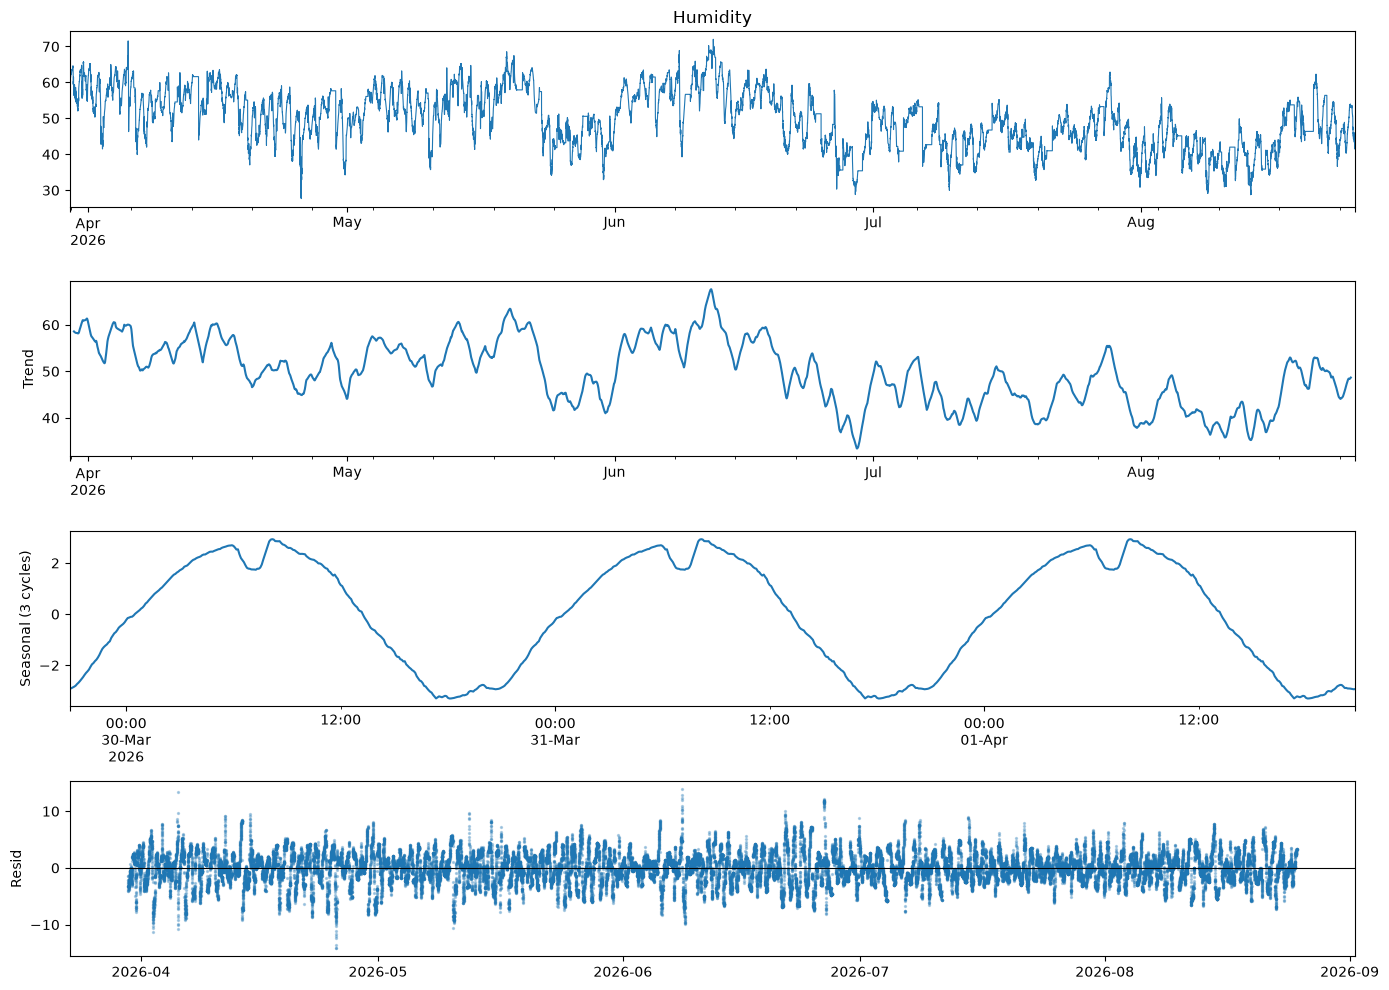

In [14]:
# run seasonal decomposition
feature = ['Humidity']
hum_result = season_decomp(df=train_df[feature],resample_size="5min")


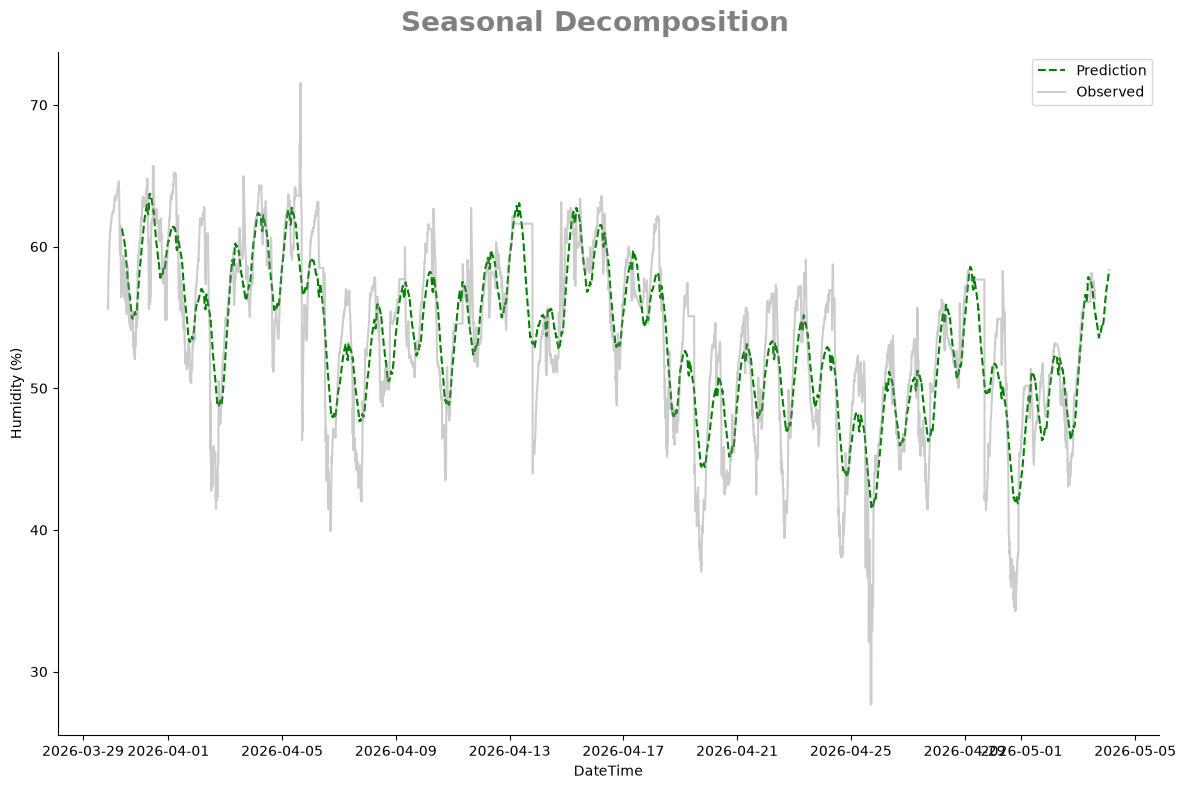

In [15]:
pred_df = (
    pd.DataFrame(
        hum_result.trend + hum_result.seasonal,
        columns=['pred']
    )
    .dropna()
)

actual_df = pd.DataFrame(hum_result.observed)
# plot results
fig = plt.figure(figsize=(12,8))

# lets take a small sample to gauge what is happening!

sample = 10000
sns.lineplot(
    data=pred_df.iloc[:sample],
    x=pred_df.index[:sample],
    y='pred',
    linestyle='--',
    color='green',
    label='Prediction'
)
sns.lineplot(
    data=actual_df.iloc[:sample],
    x=actual_df.index[:sample],
    y='Humidity',
    color='grey',
    alpha=0.4,
    label='Observed'
)


# plot clean up
plot.plot_cleanup(
    None,
    title="Seasonal Decomposition",
    xlabel="DateTime",
    ylabel="Humidity (%)"
    )


Temperature (oC) R2: 0.98


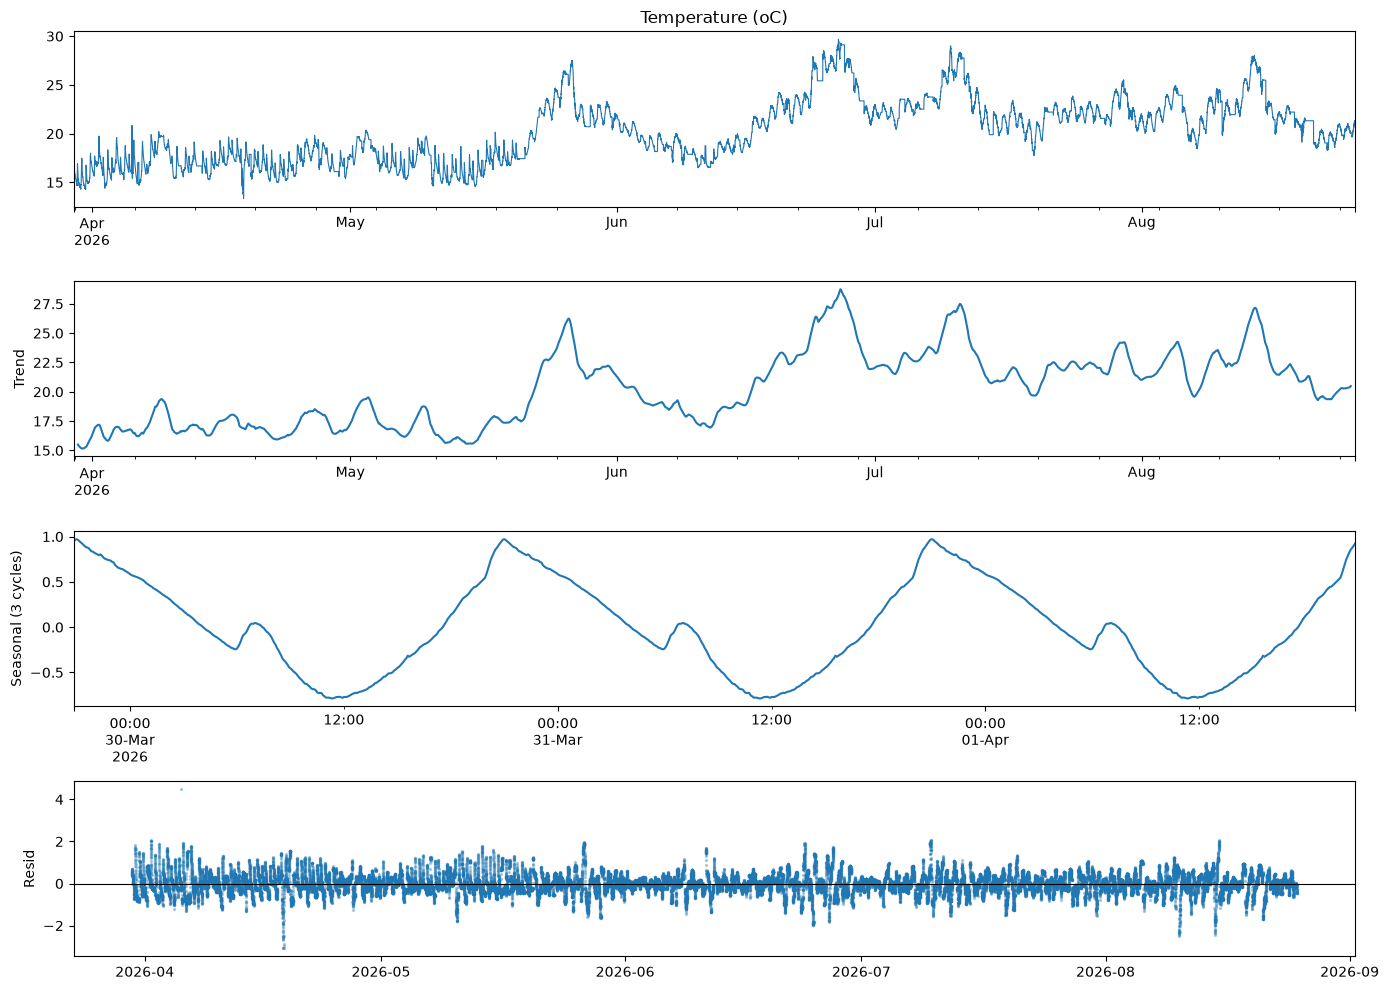

In [7]:
# run seasonal decomposition
feature = ['Temperature (oC)']
tmp_result = season_decomp(df=train_df[feature],resample_size="5min")

In [8]:
# lets compare the model to the actual data in a sample


##### Notes - Seasonal Decomposition

1. The seasonal cycles follow a similar pattern as to what I identified in the previous notebook by calculating the hourly median - Humidity peaks early in the morning then the trough is around midday. If I was to reduce condensation in the room, the above and the previous notebook suggests that a dehumidifier should be on early in the morning around 6/7am.
2. The Residual plots show random spikes where the output of the model, potentially identifying where humidity almost breaks predictibility - this could be the imputed data.
3. The residuals over time appear to follow a wave pattern in both positive and negative regions, which means in some days it does ok to predict humidity, while others it was poor. This suggests the Humidity levels on its own breaks a cycle which the model fails to capture well.
4. The trend plot shows a slow declinging humidity levels over time, further supporting my claim of hotter months equates to less humidity.
5. The plot has also identified seasonality, which is unsurpising as this is atmospheric data.

### STL

### Modelling

* Naive and seasonal naive baselines
* Classical statistical model (ARIMA / SARIMA)
* Machine learning models (lag and rolling features)
* Model comparison and evaluation

### Results